In [ ]:
# -*- coding: utf-8 -*-
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#**Imports**


In [ ]:
import os
import numpy as np
import pandas as pd
import scipy.signal as signal
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("All imports successful.")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")


All imports successful.
TensorFlow version: 2.20.0
GPU available: True


#**Configuration**

In [ ]:
# ====================================================
# CONFIGURATION — All parameters in one place
# ====================================================

# --- Path ---
BASE_PATH = "/content/drive/MyDrive/NeuroLink Dataset/NauroLink"  # Change to your path
OUTPUT_DIR = "/content/neurolink_output_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Subject names ---
# Removed weak subjects: Buruj, Buruj3, Jana1, Jana2
SUBJECTS = [
    'Buruj', 'Layal', 'Eithar',
    'Elaff', 'Hamada'
]

# --- Device settings (NeuroPawn Knight) ---
SAMPLING_RATE = 125
NUM_CHANNELS = 8
EEG_COL_START = 1    # EEG data starts at column 1
EEG_COL_END = 9      # Up to column 8 (1-8)

# --- Recording protocol ---
# Recording is ~8 seconds: 2s preparation + 4s MI + 2s rest
# Discard first 2 seconds (preparation), keep 625 samples (4s MI + 1s rest)
DISCARD_SECONDS = 2
DISCARD_SAMPLES = int(DISCARD_SECONDS * SAMPLING_RATE)  # 250 samples
MI_FIXED_LENGTH = 625

# --- Filter ---
LOW_FREQ = 8
HIGH_FREQ = 30
FILTER_ORDER = 4

# --- Windowing ---
WINDOW_SECONDS = 2
WINDOW_SIZE = int(WINDOW_SECONDS * SAMPLING_RATE)    # 250 samples
STRIDE_SECONDS = 0.5
STRIDE = int(STRIDE_SECONDS * SAMPLING_RATE)         # 62 samples
OVERLAP_PCT = (1 - STRIDE / WINDOW_SIZE) * 100       # 75%

# --- Labels ---
LABEL_MAP = {
    'backward': 0, 'forward': 1, 'left': 2, 'right': 3, 'stop': 4
}
LABEL_NAMES = ['backward', 'forward', 'left', 'right', 'stop']
NUM_CLASSES = 5

# --- Training parameters ---
BATCH_SIZE = 16
EPOCHS = 100
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.2
PATIENCE = 15

# --- Print summary ---
print("=" * 60)
print("NEUROLINK CONFIGURATION")
print("=" * 60)
print(f"  Subjects:          {len(SUBJECTS)}")
print(f"  Sampling rate:     {SAMPLING_RATE} Hz")
print(f"  EEG columns:       {EEG_COL_START}-{EEG_COL_END-1}")
print(f"  Discard first:     {DISCARD_SECONDS}s ({DISCARD_SAMPLES} samples)")
print(f"  MI segment:        {MI_FIXED_LENGTH} samples ({MI_FIXED_LENGTH/SAMPLING_RATE:.1f}s)")
print(f"  Bandpass:          {LOW_FREQ}-{HIGH_FREQ} Hz")
print(f"  Window:            {WINDOW_SIZE} samples ({WINDOW_SECONDS}s)")
print(f"  Stride:            {STRIDE} samples ({STRIDE_SECONDS}s)")
print(f"  Overlap:           {OVERLAP_PCT:.0f}%")
print(f"  Classes:           {NUM_CLASSES}")
print("=" * 60)


NEUROLINK CONFIGURATION
  Subjects:          5
  Sampling rate:     125 Hz
  EEG columns:       1-8
  Discard first:     2s (250 samples)
  MI segment:        625 samples (5.0s)
  Bandpass:          8-30 Hz
  Window:            250 samples (2s)
  Stride:            62 samples (0.5s)
  Overlap:           75%
  Classes:           5


#**Preprocessing Functions**

In [ ]:
# ====================================================
# Extract label from filename
# ====================================================
def get_label_from_filename(filename):
    basename = filename.lower().replace('.csv', '')

    # Try matching the full word first
    if '_' in basename:
        word = basename.split('_')[0]
    else:
        word = basename

    if word in LABEL_MAP:
        return LABEL_MAP[word]

    # If that didn't work, try the first character
    char_map = {'b': 0, 'f': 1, 'l': 2, 'r': 3, 's': 4}
    return char_map.get(basename[0], -1)


# ====================================================
# Load CSV file and extract EEG data
# ====================================================
def load_csv_eeg(file_path):
    """
    Reads a CSV file and extracts the correct columns (1-8).

    File structure:
      Column 0:    Packet counter (0-255) — NOT EEG!
      Columns 1-8: The 8 EEG channels
      Columns 9-10: Zeros
      Column 11:   Timestamp
      Column 12:   Zero
    """
    try:
        df = pd.read_csv(file_path, header=None)

        if df.shape[1] < EEG_COL_END:
            return None

        # Take only columns 1 to 8
        eeg_data = df.iloc[:, EEG_COL_START:EEG_COL_END].values.T

        # Must have enough samples after discarding preparation period
        min_samples = DISCARD_SAMPLES + MI_FIXED_LENGTH
        if eeg_data.shape[1] < min_samples:
            return None

        return eeg_data.astype(np.float64)
    except Exception:
        return None


# ====================================================
# Extract Motor Imagery segment
# ====================================================
def extract_mi_segment(data):
    """
    1. Discard first 2 seconds (250 samples) — preparation period
    2. Take MI_FIXED_LENGTH (625) samples = 4s MI + 1s rest
    3. Return None if the file is too short
    """
    # Discard preparation period
    mi_data = data[:, DISCARD_SAMPLES:]

    # Check that there are enough samples
    if mi_data.shape[1] < MI_FIXED_LENGTH:
        return None

    # Crop to fixed length
    return mi_data[:, :MI_FIXED_LENGTH]


# ====================================================
# Bandpass Filter (8-30 Hz)
# ====================================================
def bandpass_filter(data):
    nyquist = 0.5 * SAMPLING_RATE
    low = LOW_FREQ / nyquist
    high = HIGH_FREQ / nyquist
    b, a = signal.butter(FILTER_ORDER, [low, high], btype='band')

    filtered = np.zeros_like(data)
    for ch in range(data.shape[0]):
        filtered[ch] = signal.filtfilt(b, a, data[ch])
    return filtered


# ====================================================
# Common Average Reference (CAR)
# ====================================================
def apply_car(data):
    return data - np.mean(data, axis=0, keepdims=True)


# ====================================================
# Z-score Normalization
# ====================================================
def normalize_channels(data):
    normalized = np.zeros_like(data)
    for ch in range(data.shape[0]):
        mu = np.mean(data[ch])
        sigma = np.std(data[ch])
        if sigma > 1e-8:
            normalized[ch] = (data[ch] - mu) / sigma
        else:
            normalized[ch] = data[ch] - mu
    return normalized


# ====================================================
# Full preprocessing pipeline for a single trial
# ====================================================
def preprocess_trial(raw_data):
    data = bandpass_filter(raw_data)
    data = apply_car(data)
    data = normalize_channels(data)
    return data

print("Preprocessing functions defined.")

"""**Load and Preprocess All Subjects**"""

# ====================================================
# Load and preprocess data for each subject
# ====================================================
def load_subject_data(subject):
    folder = os.path.join(BASE_PATH, subject)
    data_list = []
    labels_list = []
    skipped = 0

    if not os.path.exists(folder):
        print(f"  WARNING: Folder not found: {folder}")
        return [], []

    # Collect all CSV files (including subfolders like train/test)
    csv_files = []
    for root, dirs, files in os.walk(folder):
        for f in files:
            if f.endswith('.csv'):
                csv_files.append(os.path.join(root, f))

    for fpath in sorted(csv_files):
        filename = os.path.basename(fpath)
        label = get_label_from_filename(filename)

        if label == -1:
            skipped += 1
            continue

        # Load EEG from the correct columns
        raw = load_csv_eeg(fpath)
        if raw is None:
            skipped += 1
            continue

        # Extract MI segment (discard preparation period)
        mi_segment = extract_mi_segment(raw)
        if mi_segment is None:       # File is shorter than required
            skipped += 1
            continue

        # Preprocess
        processed = preprocess_trial(mi_segment)

        data_list.append(processed)
        labels_list.append(label)

    if skipped > 0:
        print(f"  Skipped {skipped} files")

    return data_list, labels_list


# --- Load all subjects ---
all_subjects = {}

print("=" * 60)
print("LOADING ALL SUBJECTS")
print("=" * 60)

for sub in SUBJECTS:
    print(f"\n  Loading {sub}...")
    data_list, labels_list = load_subject_data(sub)

    if len(data_list) == 0:
        print(f"  WARNING: No data found for {sub}")
        continue

    X_sub = np.array(data_list)
    y_sub = np.array(labels_list)

    all_subjects[sub] = {'X': X_sub, 'y': y_sub}

    # Print statistics
    mi_samples = X_sub.shape[2]
    mi_duration = mi_samples / SAMPLING_RATE
    counts = np.bincount(y_sub, minlength=NUM_CLASSES)
    dist = ", ".join([f"{LABEL_NAMES[i]}:{counts[i]}" for i in range(NUM_CLASSES)])
    print(f"  {len(X_sub)} trials | Shape: {X_sub.shape} | MI: {mi_duration:.1f}s")
    print(f"  Classes: {dist}")

print("\n" + "=" * 60)
print(f"Subjects loaded: {len(all_subjects)}")
total = sum(len(v['X']) for v in all_subjects.values())
print(f"Total trials: {total}")
print("=" * 60)


Preprocessing functions defined.
LOADING ALL SUBJECTS

  Loading Buruj...
  450 trials | Shape: (450, 8, 625) | MI: 5.0s
  Classes: backward:90, forward:90, left:90, right:90, stop:90

  Loading Layal...
  450 trials | Shape: (450, 8, 625) | MI: 5.0s
  Classes: backward:90, forward:90, left:90, right:90, stop:90

  Loading Eithar...
  450 trials | Shape: (450, 8, 625) | MI: 5.0s
  Classes: backward:90, forward:90, left:90, right:90, stop:90

  Loading Elaff...
  450 trials | Shape: (450, 8, 625) | MI: 5.0s
  Classes: backward:90, forward:90, left:90, right:90, stop:90

  Loading Hamada...
  450 trials | Shape: (450, 8, 625) | MI: 5.0s
  Classes: backward:90, forward:90, left:90, right:90, stop:90

Subjects loaded: 5
Total trials: 2250


#**Windowing**

In [ ]:
# ====================================================
# Split data into overlapping windows
# ====================================================
def create_windows(X, y, window_size=WINDOW_SIZE, stride=STRIDE):
    """
    Input:  X (n_trials, 8, n_samples), y (n_trials,)
    Output: windows (n_windows, 8, window_size), labels (n_windows,)
    """
    windows = []
    labels = []

    for i in range(len(X)):
        trial = X[i]
        n_samples = trial.shape[1]
        n_win = (n_samples - window_size) // stride + 1

        for w in range(n_win):
            start = w * stride
            windows.append(trial[:, start:start + window_size])
            labels.append(y[i])

    return np.array(windows), np.array(labels)

# --- Quick test ---
test_sub = list(all_subjects.keys())[0]
test_X = all_subjects[test_sub]['X']
test_y = all_subjects[test_sub]['y']

tw, tl = create_windows(test_X, test_y)
n_per_trial = (test_X.shape[2] - WINDOW_SIZE) // STRIDE + 1

print(f"Windowing test ({test_sub}):")
print(f"  {test_X.shape[0]} trials -> {tw.shape[0]} windows")
print(f"  ~{n_per_trial} windows per trial")
print(f"  Augmentation: {tw.shape[0]/test_X.shape[0]:.1f}x")


Windowing test (Buruj):
  450 trials -> 3150 windows
  ~7 windows per trial
  Augmentation: 7.0x


#**Data Augmentation**

In [ ]:
# ====================================================
# DATA AUGMENTATION (light — scaling only)
# ====================================================

def augment_data(X_windows, y_labels):
    """
    Light augmentation: random scaling only (2x data).
    Noise and time shift removed to avoid underfitting.

    Input:  X_windows (n, 8, window_size), y_labels (n,)
    Output: X_augmented (n*2, 8, window_size), y_augmented (n*2,)
    """
    augmented_X = [X_windows.copy()]  # Keep the original
    augmented_y = [y_labels.copy()]

    n_samples = len(X_windows)

    # Random scaling (change amplitude 80%-120%)
    scales = np.random.uniform(0.8, 1.2, size=(n_samples, 1, 1))
    X_scaled = X_windows * scales
    augmented_X.append(X_scaled)
    augmented_y.append(y_labels.copy())

    # Concatenate
    X_final = np.concatenate(augmented_X, axis=0)
    y_final = np.concatenate(augmented_y, axis=0)

    # Shuffle
    shuffle_idx = np.random.permutation(len(X_final))
    X_final = X_final[shuffle_idx]
    y_final = y_final[shuffle_idx]

    print(f"  Augmentation: {n_samples} -> {len(X_final)} windows (2x)")

    return X_final, y_final

print("Data augmentation function defined (scaling only).")


Data augmentation function defined (scaling only).


#**Training Utilities**

In [ ]:
# ====================================================
# Helper utilities
# ====================================================
def prepare_for_training(X_windows, y_labels):
    """Add channel dimension + one-hot encoding"""
    X = X_windows[..., np.newaxis]
    y = to_categorical(y_labels, NUM_CLASSES)
    return X, y


def get_class_weights(y_labels):
    """Balanced class weights"""
    classes = np.unique(y_labels)
    weights = compute_class_weight('balanced', classes=classes, y=y_labels)
    return dict(zip(classes, weights))


def get_callbacks(save_path=None, patience=PATIENCE):
    cbs = [
        EarlyStopping(
            monitor='val_loss', patience=patience,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=patience // 2, min_lr=1e-6, verbose=1
        )
    ]
    if save_path:
        cbs.append(ModelCheckpoint(
            save_path, monitor='val_accuracy',
            save_best_only=True, mode='max', verbose=1
        ))
    return cbs


def plot_history(history, title=""):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['accuracy'], label='Train', lw=2)
    ax1.plot(history.history['val_accuracy'], label='Val', lw=2)
    ax1.set_title(f'{title} - Accuracy')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train', lw=2)
    ax2.plot(history.history['val_loss'], label='Val', lw=2)
    ax2.set_title(f'{title} - Loss')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_cm(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title(title, fontsize=13)
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    per_class = cm.diagonal() / (cm.sum(axis=1) + 1e-8)
    for i, name in enumerate(LABEL_NAMES):
        print(f"  {name:10s}: {per_class[i]*100:.1f}%")
    return cm


def full_eval(model, X_test, y_test_cat, y_test_labels, title=""):
    loss, acc = model.evaluate(X_test, y_test_cat, verbose=0)
    print(f"\n{'='*50}")
    print(f"  {title}")
    print(f"  Loss: {loss:.4f} | Accuracy: {acc*100:.2f}%")
    print(f"{'='*50}")

    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    print("\n" + classification_report(y_test_labels, y_pred,
                                      target_names=LABEL_NAMES, zero_division=0))
    cm = plot_cm(y_test_labels, y_pred, title)
    return acc, cm

print("Utilities defined.")


Utilities defined.


#**EEGNet Model**

In [ ]:
# ====================================================
# EEGNet
# ====================================================
def build_EEGNet(nb_classes=NUM_CLASSES, Chans=NUM_CHANNELS, Samples=WINDOW_SIZE,
                 dropoutRate=DROPOUT_RATE, kernLength=64, F1=16, D=2, F2=32):

    input1 = layers.Input(shape=(Chans, Samples, 1))

    # Block 1: Temporal + spatial filtering
    x = layers.Conv2D(F1, (1, kernLength), padding='same', use_bias=False)(input1)
    x = layers.BatchNormalization()(x)

    x = layers.DepthwiseConv2D(
        (Chans, 1), use_bias=False, depth_multiplier=D,
        depthwise_constraint=tf.keras.constraints.MaxNorm(1.),
        depthwise_regularizer=regularizers.l2(1e-4)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.AveragePooling2D((1, 4))(x)
    x = layers.Dropout(dropoutRate)(x)

    # Block 2: Separable convolution
    x = layers.SeparableConv2D(F2, (1, 16), use_bias=False, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.AveragePooling2D((1, 8))(x)
    x = layers.Dropout(dropoutRate)(x)

    # Classification
    x = layers.Flatten()(x)
    x = layers.Dense(
        nb_classes,
        kernel_constraint=tf.keras.constraints.MaxNorm(0.25),
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)
    output = layers.Activation('softmax')(x)

    return Model(inputs=input1, outputs=output)

# Display model
test_model = build_EEGNet()
test_model.summary()
print(f"\nTotal parameters: {test_model.count_params():,}")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8, 250, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 250, 16)     │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 250, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 1, 250, 32)     │           256 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 250, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 250, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 62, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 62, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 1, 62, 32)      │         1,536 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1, 62, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1, 62, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 7, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         1,125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,261 (16.64 KB)

 Trainable params: 4,101 (16.02 KB)

 Non-trainable params: 160 (640.00 B)


Total parameters: 4,261


#**LOSO + Fine-Tuning**


  LOSO + FT — Testing on: Buruj
  FT trials: 90 | Eval trials: 360
  Windows: train=10710, val=1890, ft=630, eval=2520
  Augmentation: 10710 -> 21420 windows (2x)
  Windows after aug: train=21420

  Buruj - BEFORE Fine-Tuning
  Loss: 5.1300 | Accuracy: 29.76%

              precision    recall  f1-score   support

    backward       0.27      0.21      0.24       504
     forward       0.40      0.29      0.34       504
        left       0.63      0.12      0.21       504
       right       0.22      0.47      0.30       504
        stop       0.34      0.39      0.36       504

    accuracy                           0.30      2520
   macro avg       0.37      0.30      0.29      2520
weighted avg       0.37      0.30      0.29      2520



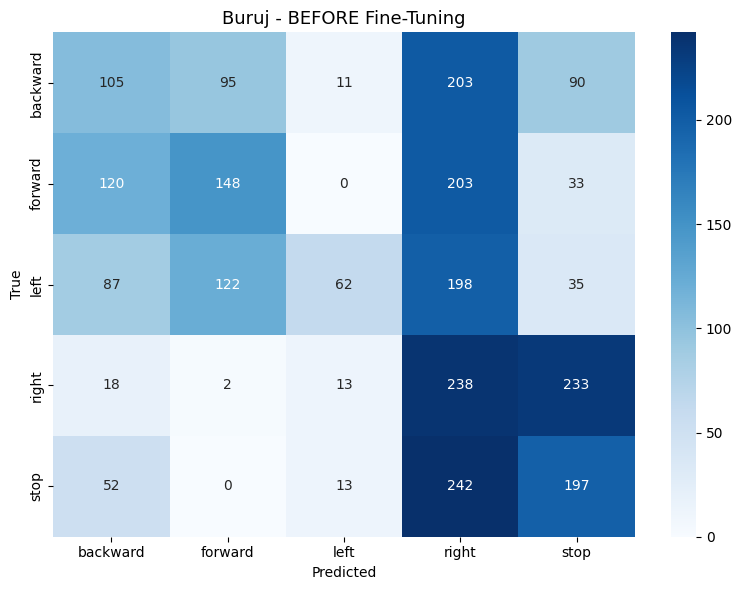

  backward  : 20.8%
  forward   : 29.4%
  left      : 12.3%
  right     : 47.2%
  stop      : 39.1%

  Buruj - AFTER Fine-Tuning
  Loss: 0.9014 | Accuracy: 73.65%

              precision    recall  f1-score   support

    backward       0.58      0.79      0.67       504
     forward       0.87      0.37      0.51       504
        left       0.71      0.89      0.79       504
       right       0.93      0.66      0.77       504
        stop       0.79      0.97      0.87       504

    accuracy                           0.74      2520
   macro avg       0.77      0.74      0.72      2520
weighted avg       0.77      0.74      0.72      2520



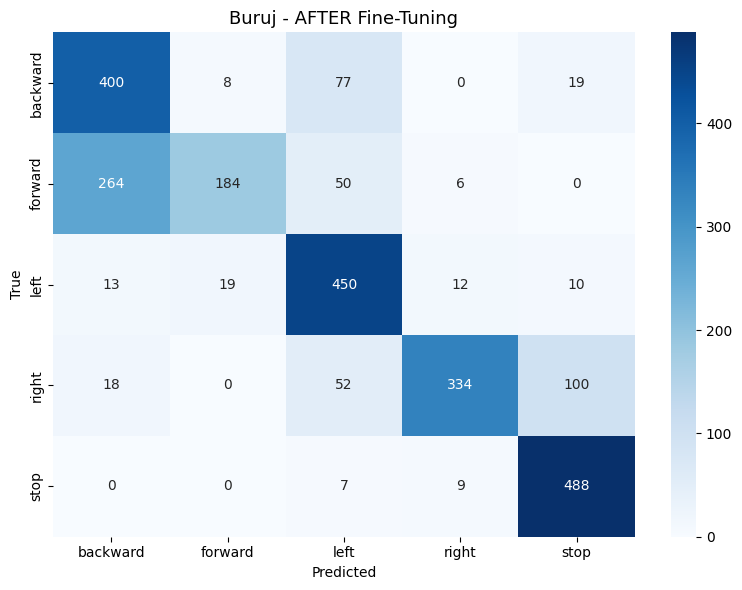

  backward  : 79.4%
  forward   : 36.5%
  left      : 89.3%
  right     : 66.3%
  stop      : 96.8%

  Improvement: +43.89%

  LOSO + FT — Testing on: Layal
  FT trials: 90 | Eval trials: 360
  Windows: train=10710, val=1890, ft=630, eval=2520
  Augmentation: 10710 -> 21420 windows (2x)
  Windows after aug: train=21420

  Layal - BEFORE Fine-Tuning
  Loss: 3.3075 | Accuracy: 20.91%

              precision    recall  f1-score   support

    backward       0.24      0.29      0.26       504
     forward       0.22      0.33      0.27       504
        left       0.17      0.10      0.13       504
       right       0.22      0.31      0.25       504
        stop       0.07      0.02      0.03       504

    accuracy                           0.21      2520
   macro avg       0.18      0.21      0.19      2520
weighted avg       0.18      0.21      0.19      2520



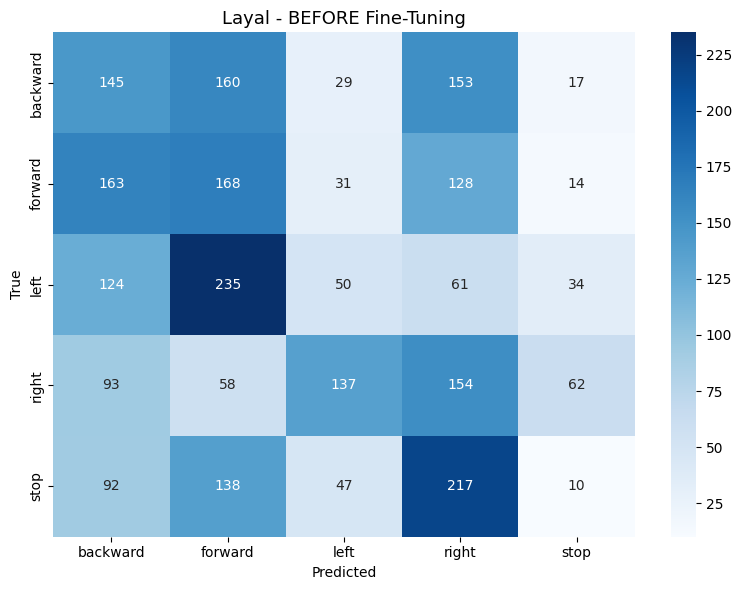

  backward  : 28.8%
  forward   : 33.3%
  left      : 9.9%
  right     : 30.6%
  stop      : 2.0%

  Layal - AFTER Fine-Tuning
  Loss: 0.8330 | Accuracy: 64.92%

              precision    recall  f1-score   support

    backward       0.63      0.50      0.56       504
     forward       0.54      0.67      0.60       504
        left       0.65      0.72      0.68       504
       right       0.70      0.60      0.64       504
        stop       0.76      0.76      0.76       504

    accuracy                           0.65      2520
   macro avg       0.65      0.65      0.65      2520
weighted avg       0.65      0.65      0.65      2520



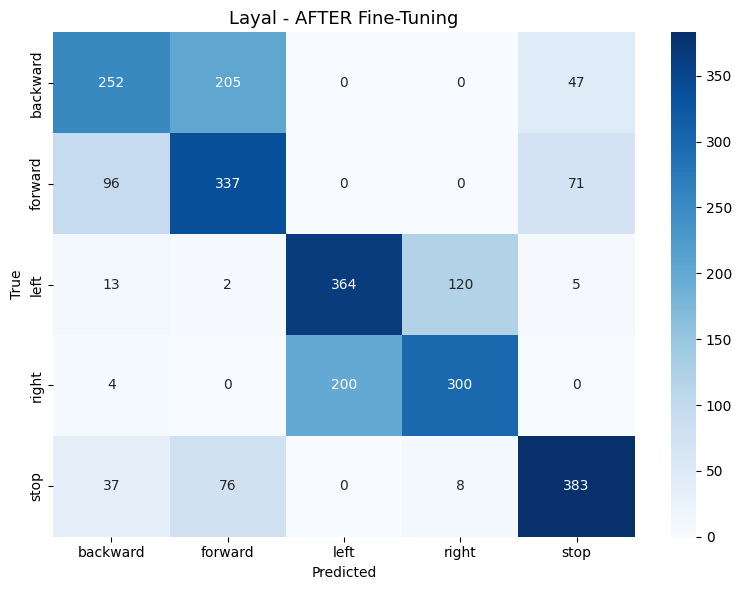

  backward  : 50.0%
  forward   : 66.9%
  left      : 72.2%
  right     : 59.5%
  stop      : 76.0%

  Improvement: +44.01%

  LOSO + FT — Testing on: Eithar
  FT trials: 90 | Eval trials: 360
  Windows: train=10710, val=1890, ft=630, eval=2520
  Augmentation: 10710 -> 21420 windows (2x)
  Windows after aug: train=21420

  Eithar - BEFORE Fine-Tuning
  Loss: 3.4313 | Accuracy: 23.89%

              precision    recall  f1-score   support

    backward       0.31      0.34      0.32       504
     forward       0.25      0.26      0.25       504
        left       0.31      0.18      0.23       504
       right       0.23      0.26      0.24       504
        stop       0.14      0.16      0.15       504

    accuracy                           0.24      2520
   macro avg       0.25      0.24      0.24      2520
weighted avg       0.25      0.24      0.24      2520



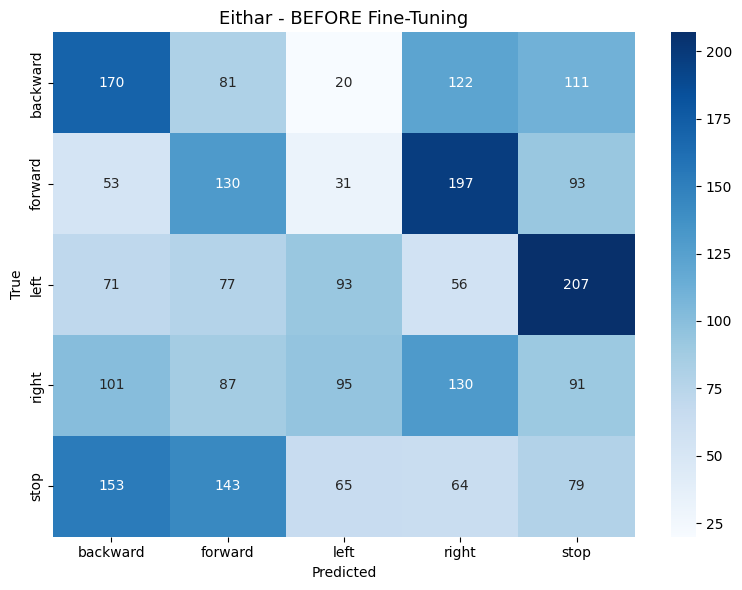

  backward  : 33.7%
  forward   : 25.8%
  left      : 18.5%
  right     : 25.8%
  stop      : 15.7%

  Eithar - AFTER Fine-Tuning
  Loss: 0.9853 | Accuracy: 65.16%

              precision    recall  f1-score   support

    backward       0.74      0.62      0.68       504
     forward       0.50      0.56      0.53       504
        left       0.71      0.80      0.75       504
       right       0.67      0.50      0.57       504
        stop       0.66      0.78      0.72       504

    accuracy                           0.65      2520
   macro avg       0.66      0.65      0.65      2520
weighted avg       0.66      0.65      0.65      2520



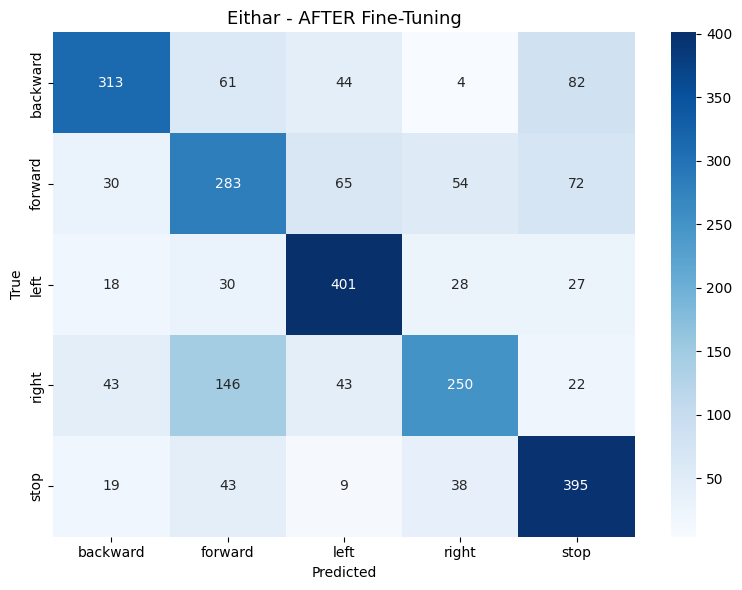

  backward  : 62.1%
  forward   : 56.2%
  left      : 79.6%
  right     : 49.6%
  stop      : 78.4%

  Improvement: +41.27%

  LOSO + FT — Testing on: Elaff
  FT trials: 90 | Eval trials: 360
  Windows: train=10710, val=1890, ft=630, eval=2520
  Augmentation: 10710 -> 21420 windows (2x)
  Windows after aug: train=21420

  Elaff - BEFORE Fine-Tuning
  Loss: 2.9242 | Accuracy: 25.75%

              precision    recall  f1-score   support

    backward       0.17      0.23      0.19       504
     forward       0.08      0.04      0.05       504
        left       0.30      0.59      0.40       504
       right       0.37      0.41      0.39       504
        stop       0.23      0.02      0.04       504

    accuracy                           0.26      2520
   macro avg       0.23      0.26      0.21      2520
weighted avg       0.23      0.26      0.21      2520



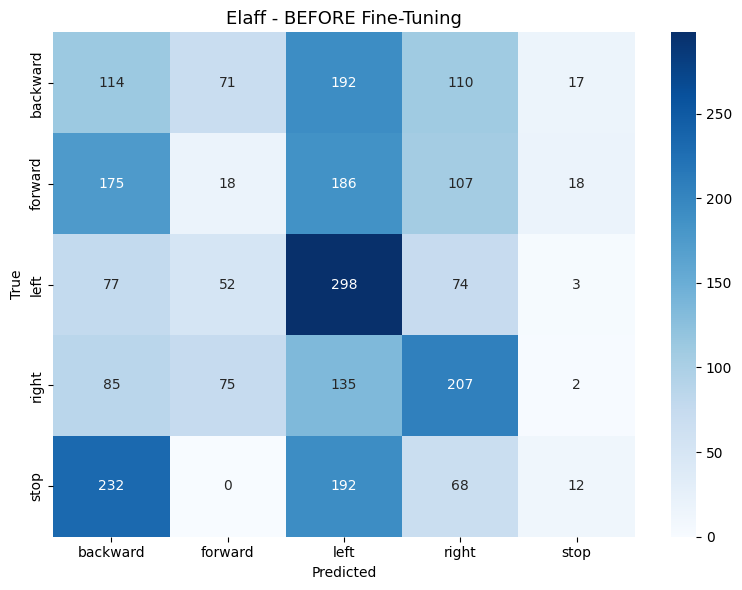

  backward  : 22.6%
  forward   : 3.6%
  left      : 59.1%
  right     : 41.1%
  stop      : 2.4%

  Elaff - AFTER Fine-Tuning
  Loss: 1.0358 | Accuracy: 65.63%

              precision    recall  f1-score   support

    backward       0.79      0.63      0.70       504
     forward       0.46      0.65      0.54       504
        left       0.67      0.68      0.68       504
       right       0.74      0.55      0.63       504
        stop       0.74      0.77      0.76       504

    accuracy                           0.66      2520
   macro avg       0.68      0.66      0.66      2520
weighted avg       0.68      0.66      0.66      2520



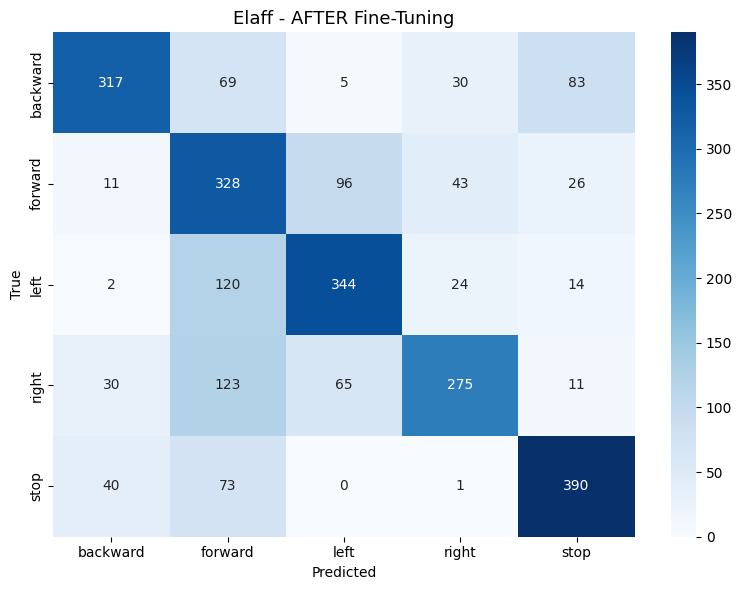

  backward  : 62.9%
  forward   : 65.1%
  left      : 68.3%
  right     : 54.6%
  stop      : 77.4%

  Improvement: +39.88%

  LOSO + FT — Testing on: Hamada
  FT trials: 90 | Eval trials: 360
  Windows: train=10710, val=1890, ft=630, eval=2520
  Augmentation: 10710 -> 21420 windows (2x)
  Windows after aug: train=21420

  Hamada - BEFORE Fine-Tuning
  Loss: 4.9238 | Accuracy: 23.97%

              precision    recall  f1-score   support

    backward       0.21      0.52      0.29       504
     forward       0.01      0.00      0.00       504
        left       0.28      0.31      0.29       504
       right       0.36      0.12      0.17       504
        stop       0.29      0.26      0.27       504

    accuracy                           0.24      2520
   macro avg       0.23      0.24      0.21      2520
weighted avg       0.23      0.24      0.21      2520



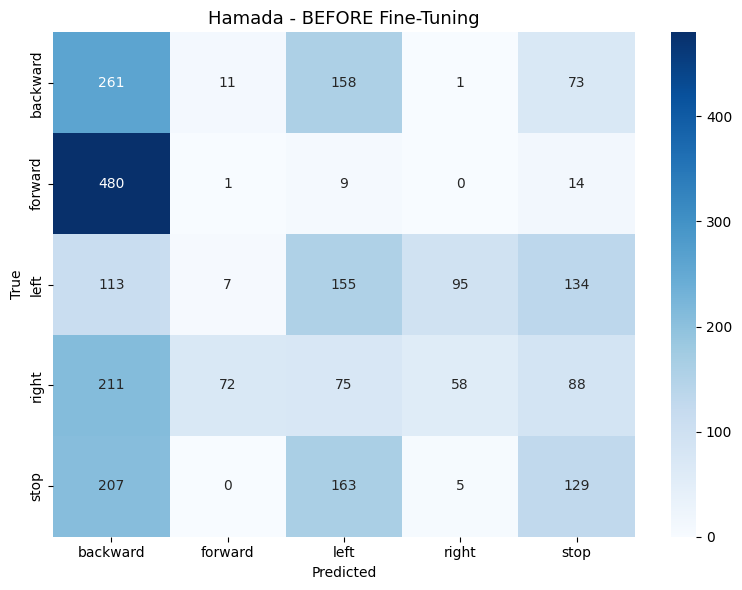

  backward  : 51.8%
  forward   : 0.2%
  left      : 30.8%
  right     : 11.5%
  stop      : 25.6%

  Hamada - AFTER Fine-Tuning
  Loss: 0.6438 | Accuracy: 76.27%

              precision    recall  f1-score   support

    backward       0.68      0.69      0.68       504
     forward       0.71      0.91      0.80       504
        left       0.89      0.53      0.67       504
       right       0.75      0.84      0.79       504
        stop       0.85      0.84      0.85       504

    accuracy                           0.76      2520
   macro avg       0.78      0.76      0.76      2520
weighted avg       0.78      0.76      0.76      2520



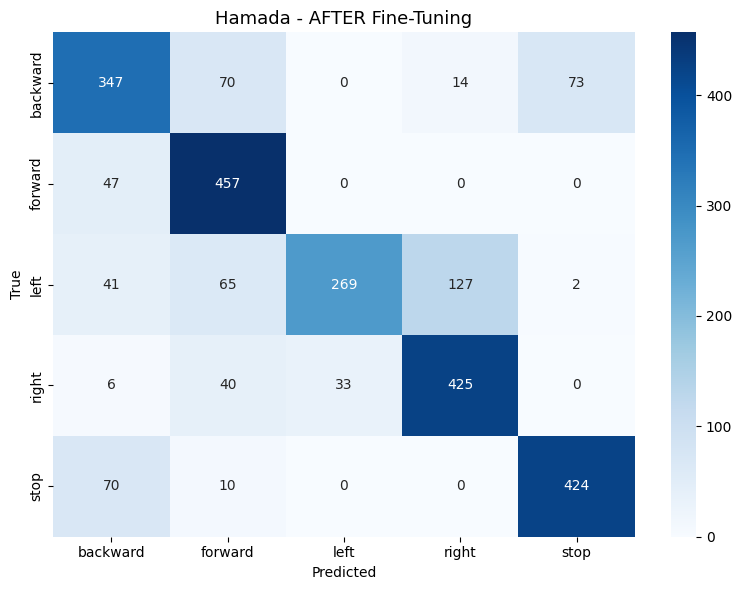

  backward  : 68.8%
  forward   : 90.7%
  left      : 53.4%
  right     : 84.3%
  stop      : 84.1%

  Improvement: +52.30%

LOSO + FINE-TUNING SUMMARY
  Subject          Before      After     Change
  ------------------------------------------
  Buruj            29.76%     73.65%    +43.89%
  Layal            20.91%     64.92%    +44.01%
  Eithar           23.89%     65.16%    +41.27%
  Elaff            25.75%     65.63%    +39.88%
  Hamada           23.97%     76.27%    +52.30%

  Mean             24.86%     69.13%    +44.27%


In [ ]:
# ====================================================
# LOSO + FINE-TUNING
# ====================================================
ft_results = {}

for test_sub in all_subjects:
    print(f"\n{'='*60}")
    print(f"  LOSO + FT — Testing on: {test_sub}")
    print(f"{'='*60}")

    # ---- Training data: all other subjects ----
    X_tr_all = np.concatenate([all_subjects[s]['X'] for s in all_subjects if s != test_sub])
    y_tr_all = np.concatenate([all_subjects[s]['y'] for s in all_subjects if s != test_sub])

    # ---- Test subject data ----
    # 20% for fine-tuning (simulating calibration)
    # 80% for final evaluation
    # Split at the TRIAL level (not windows!)
    X_te_all = all_subjects[test_sub]['X']
    y_te_all = all_subjects[test_sub]['y']

    try:
        X_ft_t, X_eval_t, y_ft_t, y_eval_t = train_test_split(
            X_te_all, y_te_all, test_size=0.8,
            random_state=42, stratify=y_te_all
        )
    except ValueError:
        X_ft_t, X_eval_t, y_ft_t, y_eval_t = train_test_split(
            X_te_all, y_te_all, test_size=0.8, random_state=42
        )

    print(f"  FT trials: {len(X_ft_t)} | Eval trials: {len(X_eval_t)}")

    # ---- Windowing AFTER splitting (very important!) ----
    Xw_tr, yw_tr = create_windows(X_tr_all, y_tr_all)
    Xw_ft, yw_ft = create_windows(X_ft_t, y_ft_t)
    Xw_eval, yw_eval = create_windows(X_eval_t, y_eval_t)

    # Validation from training data only (not from test!)
    try:
        Xw_tr, Xw_val, yw_tr, yw_val = train_test_split(
            Xw_tr, yw_tr, test_size=0.15,
            random_state=42, stratify=yw_tr
        )
    except ValueError:
        Xw_tr, Xw_val, yw_tr, yw_val = train_test_split(
            Xw_tr, yw_tr, test_size=0.15, random_state=42
        )

    print(f"  Windows: train={len(Xw_tr)}, val={len(Xw_val)}, "
          f"ft={len(Xw_ft)}, eval={len(Xw_eval)}")

    # ====== DATA AUGMENTATION (scaling only) ======
    Xw_tr, yw_tr = augment_data(Xw_tr, yw_tr)

    print(f"  Windows after aug: train={len(Xw_tr)}")

    # ---- Prepare data ----
    X_train, y_train = prepare_for_training(Xw_tr, yw_tr)
    X_val, y_val = prepare_for_training(Xw_val, yw_val)
    X_ft, y_ft = prepare_for_training(Xw_ft, yw_ft)
    X_eval, y_eval = prepare_for_training(Xw_eval, yw_eval)

    cw = get_class_weights(yw_tr)

    # ======== Phase 1: LOSO training ========
    model = build_EEGNet()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train, y_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(X_val, y_val),
        class_weight=cw,
        callbacks=[EarlyStopping(
            monitor='val_loss', patience=PATIENCE,
            restore_best_weights=True
        )],
        verbose=0
    )

    # Evaluate BEFORE Fine-Tuning
    acc_before, _ = full_eval(
        model, X_eval, y_eval, yw_eval,
        f"{test_sub} - BEFORE Fine-Tuning"
    )

    # ======== Phase 2: Fine-Tuning ========
    # Freeze Block 1 (first 7 layers) — only update Block 2 and classifier
    for layer in model.layers[:7]:
        layer.trainable = False

    # Recompile with lower learning rate
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    ft_cw = get_class_weights(yw_ft) if len(np.unique(yw_ft)) > 1 else None

    # Split FT data into train/val to avoid eval data leak
    try:
        X_ft_train, X_ft_val, y_ft_train, y_ft_val = train_test_split(
            X_ft, y_ft, test_size=0.3,
            random_state=42
        )
    except ValueError:
        X_ft_train, X_ft_val = X_ft, X_ft
        y_ft_train, y_ft_val = y_ft, y_ft

    model.fit(
        X_ft_train, y_ft_train,
        batch_size=min(16, len(X_ft_train)),
        epochs=80,
        validation_data=(X_ft_val, y_ft_val),
        class_weight=ft_cw,
        callbacks=[EarlyStopping(
            monitor='val_loss', patience=10,
            restore_best_weights=True
        )],
        verbose=0
    )

    # Evaluate AFTER Fine-Tuning
    acc_after, _ = full_eval(
        model, X_eval, y_eval, yw_eval,
        f"{test_sub} - AFTER Fine-Tuning"
    )

    change = (acc_after - acc_before) * 100
    ft_results[test_sub] = {
        'before': acc_before,
        'after': acc_after,
        'change': change
    }
    print(f"\n  Improvement: {change:+.2f}%")

# ---- Results summary ----
print("\n" + "=" * 60)
print("LOSO + FINE-TUNING SUMMARY")
print("=" * 60)
print(f"  {'Subject':<12} {'Before':>10} {'After':>10} {'Change':>10}")
print(f"  {'-'*42}")

for s, r in ft_results.items():
    print(f"  {s:<12} {r['before']*100:>9.2f}% "
          f"{r['after']*100:>9.2f}% {r['change']:>+9.2f}%")

if ft_results:
    mb = np.mean([r['before'] for r in ft_results.values()])
    ma = np.mean([r['after'] for r in ft_results.values()])
    print(f"\n  {'Mean':<12} {mb*100:>9.2f}% {ma*100:>9.2f}% "
          f"{(ma-mb)*100:>+9.2f}%")
print("=" * 60)


#**Train and Save Final Model**

In [ ]:
# ====================================================
# Train and save final model on all data
# ====================================================
print("Training final model (smaller EEGNet, with augmentation)...")

X_all = np.concatenate([all_subjects[s]['X'] for s in all_subjects])
y_all = np.concatenate([all_subjects[s]['y'] for s in all_subjects])

Xw_all, yw_all = create_windows(X_all, y_all)
Xw_all, yw_all = augment_data(Xw_all, yw_all)
X_final, y_final = prepare_for_training(Xw_all, yw_all)

X_tr, X_vl, y_tr, y_vl = train_test_split(
    X_final, y_final, test_size=0.15, random_state=42
)

model_final = build_EEGNet()
model_final.compile(
    optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
    loss='categorical_crossentropy', metrics=['accuracy']
)

history = model_final.fit(
    X_tr, y_tr,
    batch_size=BATCH_SIZE, epochs=EPOCHS,
    validation_data=(X_vl, y_vl),
    callbacks=[EarlyStopping(
        monitor='val_loss', patience=PATIENCE,
        restore_best_weights=True
    )],
    verbose=1
)

model_final.save(f'{OUTPUT_DIR}/neurolink_final_v21.h5')
print(f"\nModel saved to {OUTPUT_DIR}/neurolink_final_v21.h5")


Training final model (smaller EEGNet, with augmentation)...
  Augmentation: 15750 -> 31500 windows (2x)
Epoch 1/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.5058 - loss: 1.1744 - val_accuracy: 0.6040 - val_loss: 0.9507
Epoch 2/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5963 - loss: 0.9879 - val_accuracy: 0.6703 - val_loss: 0.8435
Epoch 3/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6269 - loss: 0.9227 - val_accuracy: 0.6889 - val_loss: 0.7938
Epoch 4/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6497 - loss: 0.8714 - val_accuracy: 0.7048 - val_loss: 0.7411
Epoch 5/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6667 - loss: 0.8363 - val_accuracy: 0.7211 - val_loss: 0.7188
Epoch 6/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6774 - loss: 0.8093 - val_accuracy: 0.7285 - val_loss: 0.7070
Epoch 7/100
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6837 - loss: 0.7949 - val_accuracy: 0.75


Model saved to /content/neurolink_output_final/neurolink_final_v21.h5


#**Final Model Evaluation**

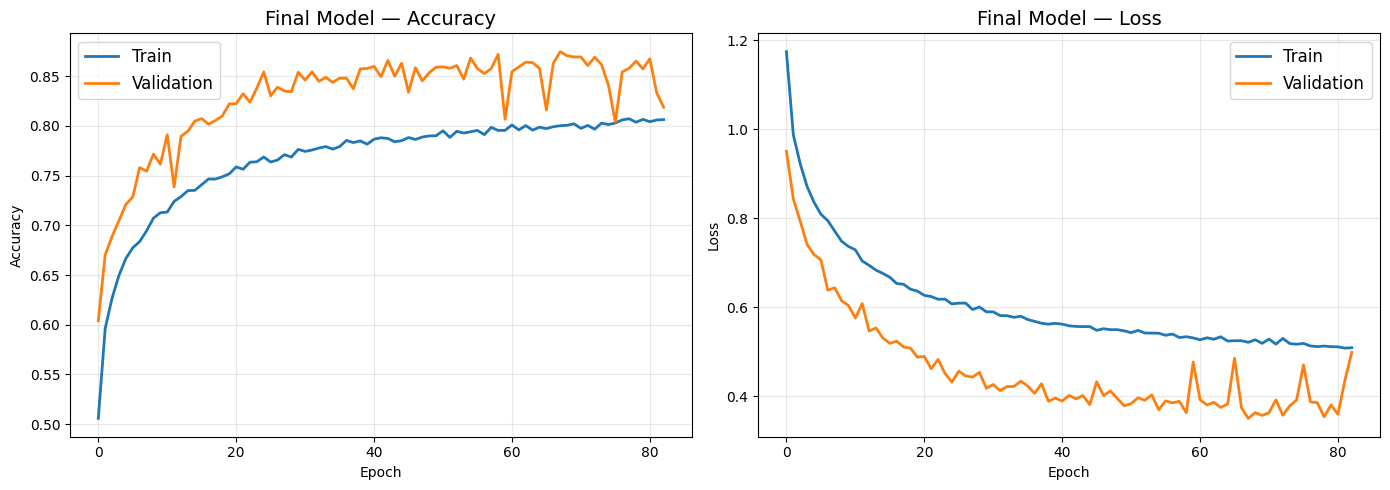

Best epoch: 68
Train Acc:  80.02%
Val Acc:    87.47%
Train Loss: 0.5216
Val Loss:   0.3507
Gap:        -7.45%


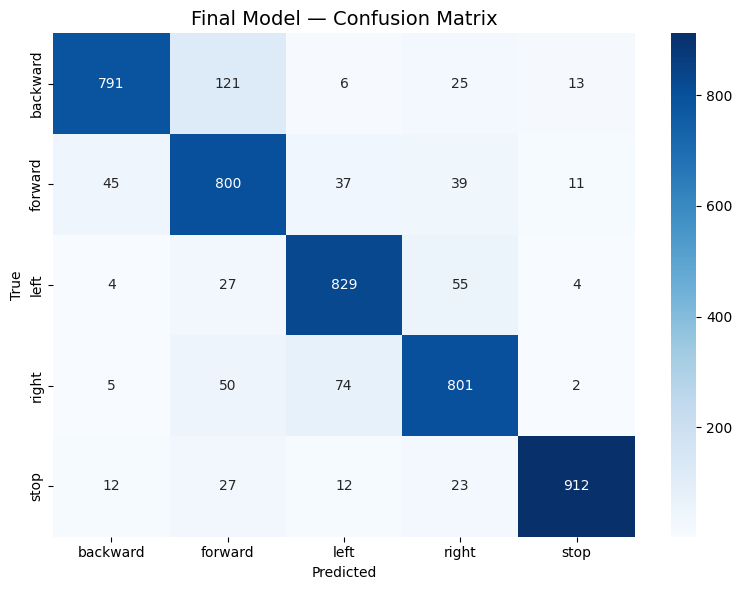


Final Model — Classification Report:
              precision    recall  f1-score   support

    backward       0.92      0.83      0.87       956
     forward       0.78      0.86      0.82       932
        left       0.87      0.90      0.88       919
       right       0.85      0.86      0.85       932
        stop       0.97      0.92      0.95       986

    accuracy                           0.87      4725
   macro avg       0.88      0.87      0.87      4725
weighted avg       0.88      0.87      0.88      4725



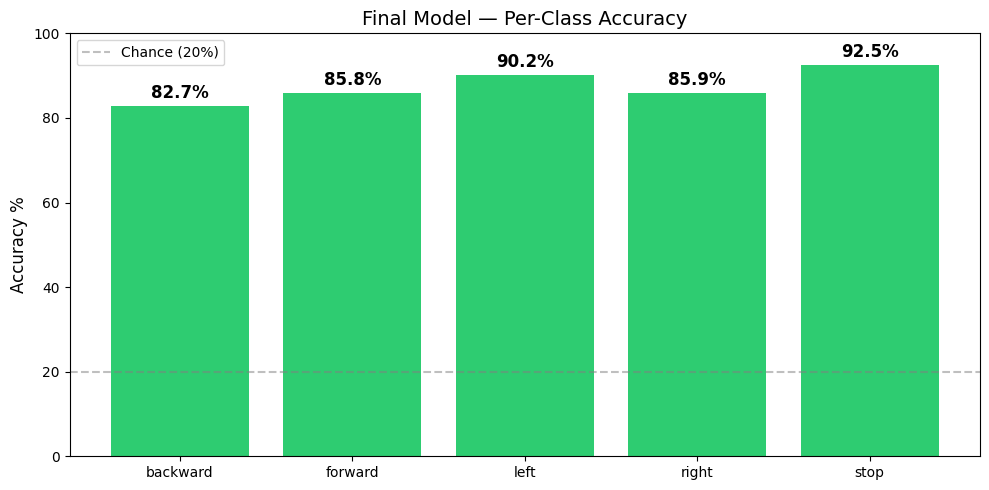

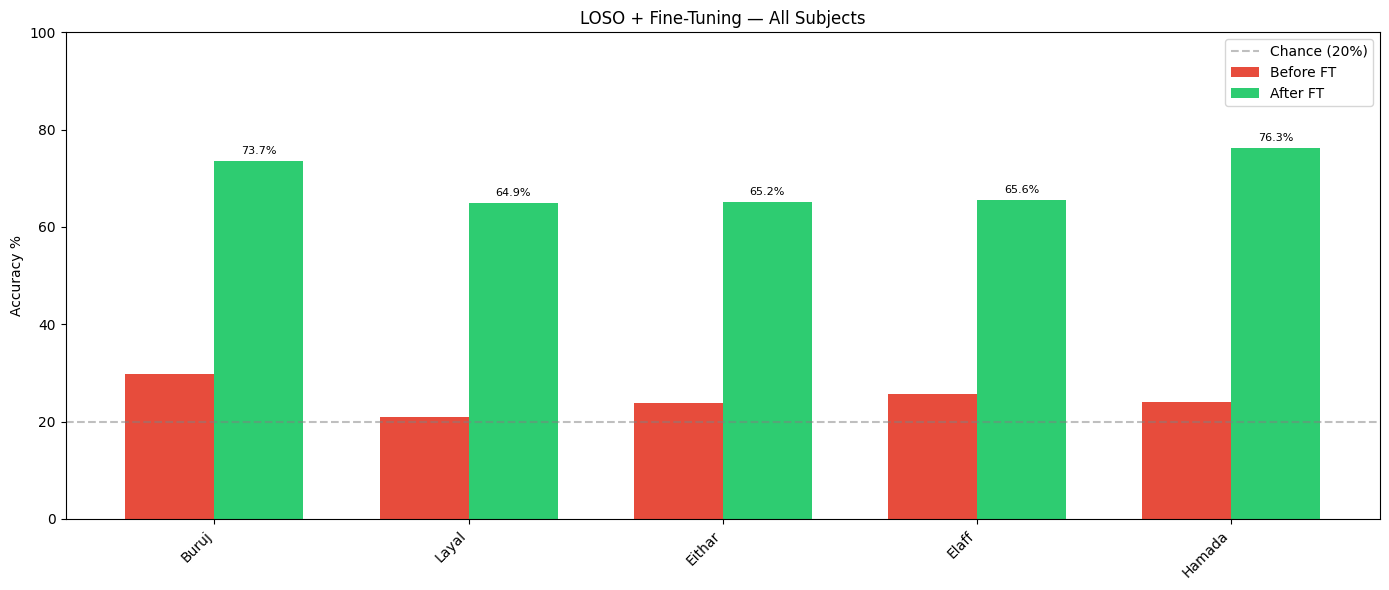

In [ ]:
# ====================================================
# Final Model Evaluation
# ====================================================

# ---- 1. Loss & Accuracy Curves ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train', lw=2)
ax1.plot(history.history['val_accuracy'], label='Validation', lw=2)
ax1.set_title('Final Model — Accuracy', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', lw=2)
ax2.plot(history.history['val_loss'], label='Validation', lw=2)
ax2.set_title('Final Model — Loss', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = np.argmin(history.history['val_loss'])
print(f"Best epoch: {best_epoch + 1}")
print(f"Train Acc:  {history.history['accuracy'][best_epoch]*100:.2f}%")
print(f"Val Acc:    {history.history['val_accuracy'][best_epoch]*100:.2f}%")
print(f"Train Loss: {history.history['loss'][best_epoch]:.4f}")
print(f"Val Loss:   {history.history['val_loss'][best_epoch]:.4f}")
print(f"Gap:        {(history.history['accuracy'][best_epoch] - history.history['val_accuracy'][best_epoch])*100:.2f}%")

# ---- 2. Confusion Matrix ----
y_pred_probs = model_final.predict(X_vl, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_vl, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.title('Final Model — Confusion Matrix', fontsize=14)
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# ---- 3. Classification Report ----
print("\nFinal Model — Classification Report:")
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0))

# ---- 4. Per-Class Accuracy Bar Chart ----
per_class = cm.diagonal() / (cm.sum(axis=1) + 1e-8) * 100
colors = ['#e74c3c' if acc < 60 else '#f39c12' if acc < 75 else '#2ecc71' for acc in per_class]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(LABEL_NAMES, per_class, color=colors)
ax.set_ylabel('Accuracy %', fontsize=12)
ax.set_title('Final Model — Per-Class Accuracy', fontsize=14)
ax.set_ylim(0, 100)
ax.axhline(y=20, color='gray', linestyle='--', alpha=0.5, label='Chance (20%)')
ax.legend()

for bar, acc in zip(bars, per_class):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{acc:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# ---- 5. LOSO Summary Bar Chart ----
if ft_results:
    subjects = list(ft_results.keys())
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(subjects))
    width = 0.35

    bars1 = ax.bar(x - width/2, [ft_results[s]['before']*100 for s in subjects], width, label='Before FT', color='#e74c3c')
    bars2 = ax.bar(x + width/2, [ft_results[s]['after']*100 for s in subjects], width, label='After FT', color='#2ecc71')

    ax.set_ylabel('Accuracy %')
    ax.set_title('LOSO + Fine-Tuning — All Subjects')
    ax.set_xticks(x)
    ax.set_xticklabels(subjects, rotation=45, ha='right')
    ax.axhline(y=20, color='gray', linestyle='--', alpha=0.5, label='Chance (20%)')
    ax.legend()
    ax.set_ylim(0, 100)

    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.show()

#**DON'T FORGET THIS CELL!!**

In [ ]:
import shutil
shutil.copy(f'{OUTPUT_DIR}/neurolink_final_v21.h5',
            '/content/drive/MyDrive/neurolink_final_v21.h5')
print("Model copied to Google Drive!")

Model copied to Google Drive!
